# Q8 · Notebook 02: Analysis

Uses `Q8_outputs/q8_tract_table.csv` and `Q8_outputs/q8_food_shelf_sites_2024.csv` from notebook 01.

The brief asks three things, answered in order:

1. **Reach.** Does the food shelf network sufficiently reach low-income, low-access (LILA) areas?
2. **Fill or repeat.** Does the network fill the retail gap, or repeat the same pattern as the retail market?
3. **Place.** How does this differ across locations?

Then: robustness checks, a gap list of tracts to act on, and maps.

**Weights.** Results are weighted by **people in poverty** (2020 population × 2020–24 poverty rate), so a tract counts in proportion to the people the question is about. Comparison group for LILA tracts = low-income tracts that are *not* low-access, so income is held roughly constant and only grocery access differs.

In [1]:
import os, warnings, numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import spearmanr
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)

DATA, OUT = 'Data for Q8', 'Q8_outputs'   # same folders as notebook 01
FIG = f'{OUT}/figures'; os.makedirs(FIG, exist_ok=True)

t = pd.read_csv(f'{OUT}/q8_tract_table.csv', dtype={'GEOID': str})
sites = pd.read_csv(f'{OUT}/q8_food_shelf_sites_2024.csv')
groc = pd.read_csv(f'{OUT}/q8_grocery_stores_2024.csv')

# chart style: one accent, everything else grey
ACCENT, ACCENT2, GREY, LIGHT = '#2a78d6', '#eb6834', '#9a9893', '#d9d8d4'
INK, INK2 = '#0b0b0b', '#52514e'
plt.rcParams.update({'font.size': 11, 'axes.edgecolor': LIGHT, 'axes.labelcolor': INK2, 'xtick.color': INK2,
                     'ytick.color': INK2, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 13, 'axes.titlecolor': INK,
                     'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight'})

GROUP_ORDER = ['LILA', 'Low income, not low access', 'Not low income']
PLACE_ORDER = ['Metro core (Hennepin, Ramsey)', 'Metro suburbs', 'Greater MN, urban', 'Greater MN, rural']

def wmean(x, w):
    m = x.notna() & w.notna()
    return np.average(x[m], weights=w[m]) if w[m].sum() > 0 else np.nan

def wmedian(x, w):
    m = x.notna() & w.notna(); x, w = x[m].values, w[m].values
    o = np.argsort(x); c = np.cumsum(w[o]); return x[o][np.searchsorted(c, c[-1] / 2)]

def reach_table(df, by, flag='lila', w='pop_poverty'):
    rows = []
    for g, d in df.groupby(by, sort=False):
        W = d[w]
        rows.append({by: g, 'tracts': len(d), 'people in poverty': W.sum(),
                     'median miles to food shelf': wmedian(d.mi_foodshelf, W),
                     'median miles to full grocery': wmedian(d.mi_grocery, W),
                     '% within USDA distance of a food shelf': 100 * wmean(d.fs_within_la_threshold, W),
                     '% with food shelf closer than grocery': 100 * wmean((d.mi_foodshelf < d.mi_grocery).astype(float), W),
                     'lbs / person in poverty / yr (10 mi)': wmean(d.lbs_per_poor_10mi, W),
                     'visits / person in poverty / yr (10 mi)': wmean(d.visits_per_poor_10mi, W)})
    return pd.DataFrame(rows).set_index(by)

## Context: who lives in LILA tracts?

In [2]:
ctx = (t.groupby('group')
         .apply(lambda d: pd.Series({'tracts': len(d), 'people in poverty': d.pop_poverty.sum(),
                                     '% urban tracts': 100 * d.Urban.mean(),
                                     '% households without a vehicle': 100 * d.TractHUNV.sum() / d.OHU2020.sum(),
                                     '% households on SNAP': 100 * d.TractSNAP.sum() / d.OHU2020.sum(),
                                     'poverty rate %': 100 * d.pop_poverty.sum() / d.POP2020.sum()}))
         .reindex(GROUP_ORDER).round(1))
ctx

,tracts,people in poverty,% urban tracts,% households without a vehicle,% households on SNAP,poverty rate %
group,,,,,,
LILA,141.0,85855.1,75.2,8.3,11.5,15.6
"Low income, not low access",397.0,220083.5,65.2,12.3,15.2,16.7
Not low income,964.0,236916.7,64.2,4.7,5.0,6.2


## 1. Reach: does the network reach LILA areas?

In [3]:
reach = reach_table(t, 'group').reindex(GROUP_ORDER).round(1)
reach.to_csv(f'{OUT}/q8_reach_by_group.csv')
reach

,tracts,people in poverty,median miles to food shelf,median miles to full grocery,% within USDA distance of a food shelf,% with food shelf closer than grocery,lbs / person in poverty / yr (10 mi),visits / person in poverty / yr (10 mi)
group,,,,,,,,
LILA,141,85855.1,0.9,0.8,64.7,51.2,240.7,4.2
"Low income, not low access",397,220083.5,0.8,0.6,71.6,43.0,290.0,5.6
Not low income,964,236916.7,1.7,1.0,54.6,30.2,292.6,5.2


Distance bands: share of people in poverty living within each distance of a food shelf.

In [4]:
bands = [1, 2, 5, 10]
band = pd.DataFrame({f'≤{b} mi': t.groupby('group').apply(lambda d: 100 * wmean((d.mi_foodshelf <= b).astype(float), d.pop_poverty))
                     for b in bands}).reindex(GROUP_ORDER).round(1)
band

,≤1 mi,≤2 mi,≤5 mi,≤10 mi
group,,,,
LILA,57.3,80.8,88.1,94.4
"Low income, not low access",57.7,83.5,92.2,96.7
Not low income,29.2,57.1,84.1,96.3


In [5]:
# Within each place type, compare LILA to low-income-not-low-access (so the urban/rural mix does not drive the answer)
li = t[t.low_income == 1]
reach_place = (li.groupby(['place', 'group']).apply(lambda d: pd.Series({
                   'tracts': len(d),
                   'median miles to food shelf': wmedian(d.mi_foodshelf, d.pop_poverty),
                   '% within USDA distance of a food shelf': 100 * wmean(d.fs_within_la_threshold, d.pop_poverty),
                   'lbs / person in poverty (10 mi)': wmean(d.lbs_per_poor_10mi, d.pop_poverty)}))
                 .round(1))
reach_place

tracts  median miles to food shelf  % within USDA distance of a food shelf  lbs / person in poverty (10 mi)
place                         group                                                                                                                                  
Greater MN, rural             LILA                          35.0                         9.4                                    58.5                             94.3
                              Low income, not low access   135.0                         2.5                                    86.5                            171.7
Greater MN, urban             LILA                          71.0                         0.8                                    68.5                            224.6
                              Low income, not low access    71.0                         0.9                                    59.4                            212.5
Metro core (Hennepin, Ramsey) LILA                          20.0                         0.8                                    65.2                            354.4
                              Low income, not low access   146.0                         0.5                                    76.0                            379.1
Metro suburbs                 LILA                          15.0                         1.1                                    46.4                            275.4
                              Low income, not low access    45.0                         1.1                                    38.6                            290.7

**Chart 1.** Share of people in poverty with a food shelf inside the USDA low-access distance (1 mile urban, 10 miles rural).

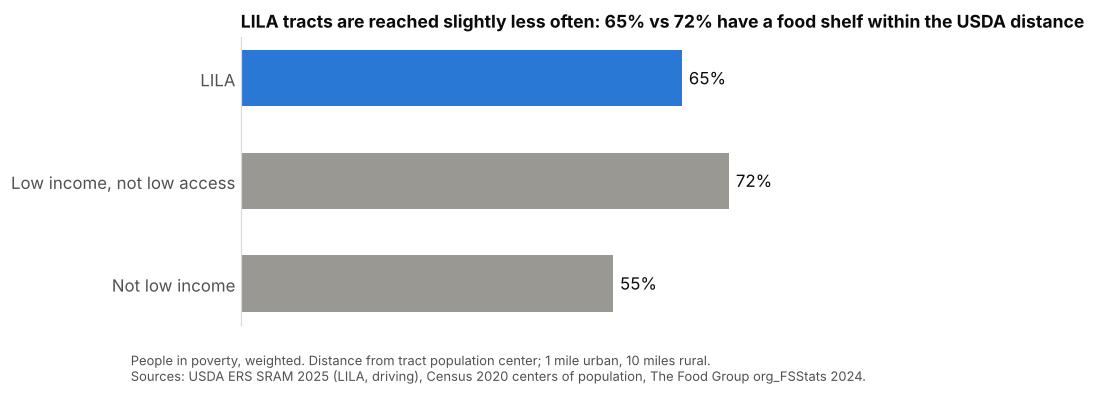

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.4))
vals = reach['% within USDA distance of a food shelf']
colors = [ACCENT if g == 'LILA' else GREY for g in vals.index]
ax.barh(vals.index[::-1], vals.values[::-1], color=colors[::-1], height=0.55)
for y, v in enumerate(vals.values[::-1]):
    ax.text(v + 1, y, f'{v:.0f}%', va='center', color=INK, fontsize=11)
ax.set_xlim(0, 100); ax.set_xticks([]); ax.spines['bottom'].set_visible(False); ax.tick_params(axis='y', length=0)
ax.set_title(f"LILA tracts are reached slightly less often: {vals['LILA']:.0f}% vs {vals['Low income, not low access']:.0f}% have a food shelf within the USDA distance", loc='left', fontsize=11.5)
fig.text(0, -0.04, 'People in poverty, weighted. Distance from tract population center; 1 mile urban, 10 miles rural.\n'
         'Sources: USDA ERS SRAM 2025 (LILA, driving), Census 2020 centers of population, The Food Group org_FSStats 2024.',
         fontsize=8.5, color=INK2)
fig.savefig(f'{FIG}/q8_chart1_reach.png'); plt.show()

## 2. Fill or repeat: does the network follow the grocery map?

If food shelves **fill** the retail gap, they should be relatively closer than grocery stores in places where grocery stores are far. If they **repeat** the retail pattern, distance to a food shelf rises one-for-one with distance to a grocery store.

Test across all low-income tracts: regress log miles to the nearest food shelf on log miles to the nearest full-service grocery, controlling for urban/rural. A slope near 1 means the network repeats the retail map; a slope near 0 means food shelves are placed independently of it; below 0 would mean they fill gaps.

In [7]:
li = t[(t.low_income == 1) & (t.pop_poverty > 0)].copy()
li['log_fs'] = np.log(li.mi_foodshelf); li['log_gr'] = np.log(li.mi_grocery)
rho_all, p_all = spearmanr(li.mi_grocery, li.mi_foodshelf)
fit = smf.wls('log_fs ~ log_gr + Urban', data=li, weights=li.pop_poverty).fit(cov_type='HC1')
fit_int = smf.wls('log_fs ~ log_gr * Urban', data=li, weights=li.pop_poverty).fit(cov_type='HC1')
print(f'Spearman rank correlation, grocery vs food shelf distance (low-income tracts): {rho_all:.2f} (p={p_all:.1e})')
print(f'Elasticity (slope): {fit.params.log_gr:.2f}  95% CI [{fit.conf_int().loc["log_gr",0]:.2f}, {fit.conf_int().loc["log_gr",1]:.2f}]')
fit_int.summary().tables[1]

Spearman rank correlation, grocery vs food shelf distance (low-income tracts): 0.63 (p=2.3e-61)
Elasticity (slope): 0.58  95% CI [0.46, 0.69]


,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,0.1677,0.106,1.580,0.114,-0.040,0.376
log_gr,0.8157,0.056,14.545,0.000,0.706,0.926
Urban,-0.4440,0.130,-3.408,0.001,-0.699,-0.189
log_gr:Urban,-0.4881,0.098,-5.003,0.000,-0.679,-0.297


In [8]:
# Slope by place type
rows = []
for p, d in li.groupby('place'):
    if len(d) < 15: continue
    f = smf.wls('log_fs ~ log_gr', data=d, weights=d.pop_poverty).fit(cov_type='HC1')
    rows.append({'place': p, 'tracts': len(d), 'slope': f.params.log_gr,
                 'ci_low': f.conf_int().loc['log_gr', 0], 'ci_high': f.conf_int().loc['log_gr', 1],
                 'spearman': spearmanr(d.mi_grocery, d.mi_foodshelf)[0]})
slopes = pd.DataFrame(rows).set_index('place').reindex(PLACE_ORDER).round(2)
slopes.to_csv(f'{OUT}/q8_fill_or_repeat_by_place.csv')
slopes

,tracts,slope,ci_low,ci_high,spearman
place,,,,,
"Metro core (Hennepin, Ramsey)",166,0.33,0.09,0.57,0.24
Metro suburbs,60,0.07,-0.24,0.38,0.09
"Greater MN, urban",142,0.16,-0.10,0.42,0.14
"Greater MN, rural",170,0.82,0.71,0.93,0.70


**Check: is the rural slope just remoteness?** Both distances grow where people are spread out, so the slope is re-estimated controlling for log population density.

In [9]:
aland = gpd.read_file(f'{DATA}/tl_2024_27_tract/tl_2024_27_tract.dbf', ignore_geometry=True)[['GEOID', 'ALAND']]
li = li.merge(aland, on='GEOID', how='left')
li['log_density'] = np.log(li.POP2020 / (li.ALAND / 2.59e6))   # people per square mile
rows = []
for p, d in [('All low-income tracts', li)] + list(li.groupby('place')):
    f = smf.wls('log_fs ~ log_gr + log_density' + (' + Urban' if p.startswith('All') else ''), data=d, weights=d.pop_poverty).fit(cov_type='HC1')
    rows.append({'place': p, 'slope, density-controlled': f.params.log_gr,
                 'ci_low': f.conf_int().loc['log_gr', 0], 'ci_high': f.conf_int().loc['log_gr', 1]})
slopes_d = pd.DataFrame(rows).set_index('place').round(2)
slopes_d.to_csv(f'{OUT}/q8_fill_or_repeat_density_controlled.csv')
slopes_d

,"slope, density-controlled",ci_low,ci_high
place,,,
All low-income tracts,0.40,0.28,0.52
"Greater MN, rural",0.55,0.38,0.71
"Greater MN, urban",0.17,-0.09,0.43
"Metro core (Hennepin, Ramsey)",0.23,-0.03,0.50
Metro suburbs,0.02,-0.32,0.36


Second test: **in LILA tracts, the grocery store is by definition far. Is the food shelf any closer?** Ratio of food shelf distance to grocery distance, LILA vs comparison.

In [10]:
li['fs_to_grocery_ratio'] = li.mi_foodshelf / li.mi_grocery
ratio = li.groupby('group').apply(lambda d: pd.Series({
    'median miles to grocery': wmedian(d.mi_grocery, d.pop_poverty),
    'median miles to food shelf': wmedian(d.mi_foodshelf, d.pop_poverty),
    'median food shelf ÷ grocery distance': wmedian(d.fs_to_grocery_ratio, d.pop_poverty),
    '% food shelf closer than grocery': 100 * wmean((d.fs_to_grocery_ratio < 1).astype(float), d.pop_poverty)})).round(2)
ratio

,median miles to grocery,median miles to food shelf,median food shelf ÷ grocery distance,% food shelf closer than grocery
group,,,,
LILA,0.85,0.88,0.98,51.16
"Low income, not low access",0.59,0.81,1.11,43.01


**Chart 2.** Each dot is a low-income tract. Left: Twin Cities metro and Greater MN cities. Right: rural Greater MN. Dots on the dashed line have a food shelf exactly as far away as the nearest grocery store; the solid line is the fitted slope.

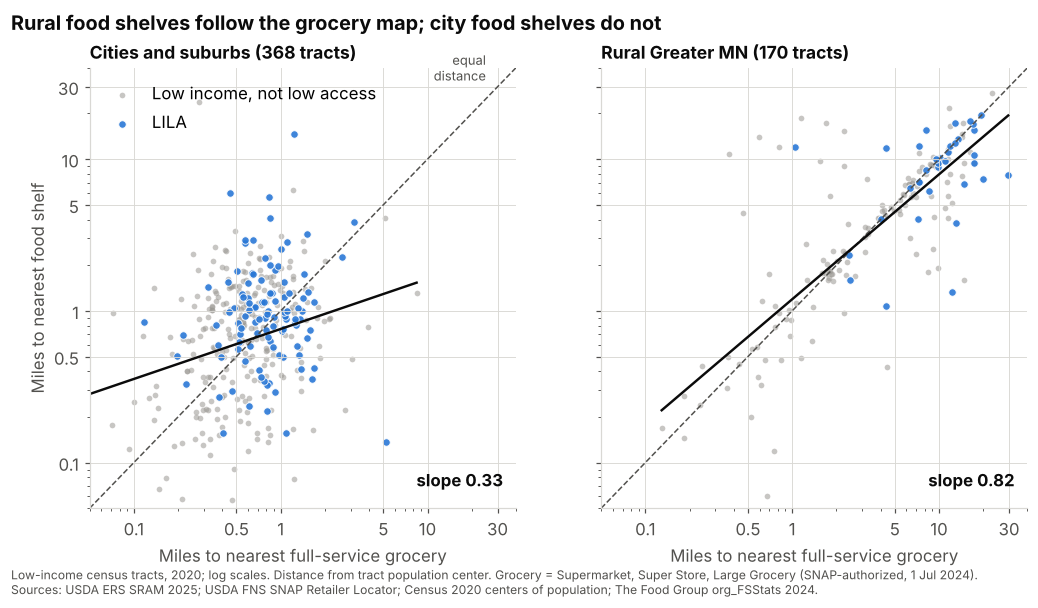

In [11]:
panels = [('Cities and suburbs', li[li.place != 'Greater MN, rural']), ('Rural Greater MN', li[li.place == 'Greater MN, rural'])]
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharey=True)
lim = [0.05, 40]; ticks = [0.1, 0.5, 1, 5, 10, 30]
for ax, (name, d) in zip(axes, panels):
    nl, yl = d[d.lila == 0], d[d.lila == 1]
    ax.scatter(nl.mi_grocery, nl.mi_foodshelf, s=14, color=GREY, alpha=0.55, linewidths=0, label='Low income, not low access')
    ax.scatter(yl.mi_grocery, yl.mi_foodshelf, s=24, color=ACCENT, alpha=0.9, edgecolor='white', linewidth=0.6, label='LILA')
    ax.plot(lim, lim, color=INK2, lw=1, ls='--')
    f = smf.wls('log_fs ~ log_gr', data=d, weights=d.pop_poverty).fit()
    xs = np.linspace(np.log(d.mi_grocery.min()), np.log(d.mi_grocery.max()), 50)
    ax.plot(np.exp(xs), np.exp(f.params.Intercept + f.params.log_gr * xs), color=INK, lw=1.6)
    ax.text(0.97, 0.05, f'slope {f.params.log_gr:.2f}', transform=ax.transAxes, ha='right', fontsize=11, color=INK, fontweight='bold')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xticks(ticks); ax.set_xticklabels([str(x) for x in ticks]); ax.set_yticks(ticks); ax.set_yticklabels([str(x) for x in ticks])
    ax.set_xlabel('Miles to nearest full-service grocery'); ax.grid(color=LIGHT, lw=0.6)
    ax.set_title(f'{name} ({len(d)} tracts)', loc='left', fontsize=11.5)
axes[0].set_ylabel('Miles to nearest food shelf'); axes[0].legend(frameon=False, loc='upper left')
axes[0].text(25, 33, 'equal\ndistance', color=INK2, fontsize=8.5, ha='right')
fig.suptitle('Rural food shelves follow the grocery map; city food shelves do not', x=0.06, ha='left', fontsize=13, fontweight='bold', color=INK)
fig.text(0.06, -0.04, 'Low-income census tracts, 2020; log scales. Distance from tract population center. Grocery = Supermarket, Super Store, Large Grocery (SNAP-authorized, 1 Jul 2024).\n'
         'Sources: USDA ERS SRAM 2025; USDA FNS SNAP Retailer Locator; Census 2020 centers of population; The Food Group org_FSStats 2024.', fontsize=8, color=INK2)
fig.savefig(f'{FIG}/q8_chart2_fill_or_repeat.png'); plt.show()

## 3. Place: how does it differ across locations?

In [12]:
lila = t[t.lila == 1]
place_tbl = reach_table(lila, 'place').reindex([p for p in PLACE_ORDER if p in lila.place.unique()]).round(1)
tribal_tbl = reach_table(t[t.low_income == 1], 'tribal').rename(index={0: 'Low-income, not tribal area', 1: 'Low-income, tribal area (≥50%)'}).round(1)
place_tbl.to_csv(f'{OUT}/q8_lila_by_place.csv')
place_tbl

,tracts,people in poverty,median miles to food shelf,median miles to full grocery,% within USDA distance of a food shelf,% with food shelf closer than grocery,lbs / person in poverty / yr (10 mi),visits / person in poverty / yr (10 mi)
place,,,,,,,,
"Metro core (Hennepin, Ramsey)",20,18720.3,0.8,0.8,65.2,58.2,354.4,7.5
Metro suburbs,15,7160.6,1.1,0.9,46.4,40.0,275.4,4.8
"Greater MN, urban",71,49145.5,0.8,0.8,68.5,46.4,224.6,3.5
"Greater MN, rural",35,10828.8,9.4,10.9,58.5,67.7,94.3,1.7


In [13]:
tribal_tbl

,tracts,people in poverty,median miles to food shelf,median miles to full grocery,% within USDA distance of a food shelf,% with food shelf closer than grocery,lbs / person in poverty / yr (10 mi),visits / person in poverty / yr (10 mi)
tribal,,,,,,,,
"Low-income, not tribal area",528,298814.4,0.8,0.7,69.9,45.4,279.9,5.3
"Low-income, tribal area (≥50%)",10,7124.3,5.7,11.3,61.7,39.9,117.7,2.0


**Chart 3.** LILA tracts by place: median miles to the nearest food shelf vs the nearest full-service grocery.

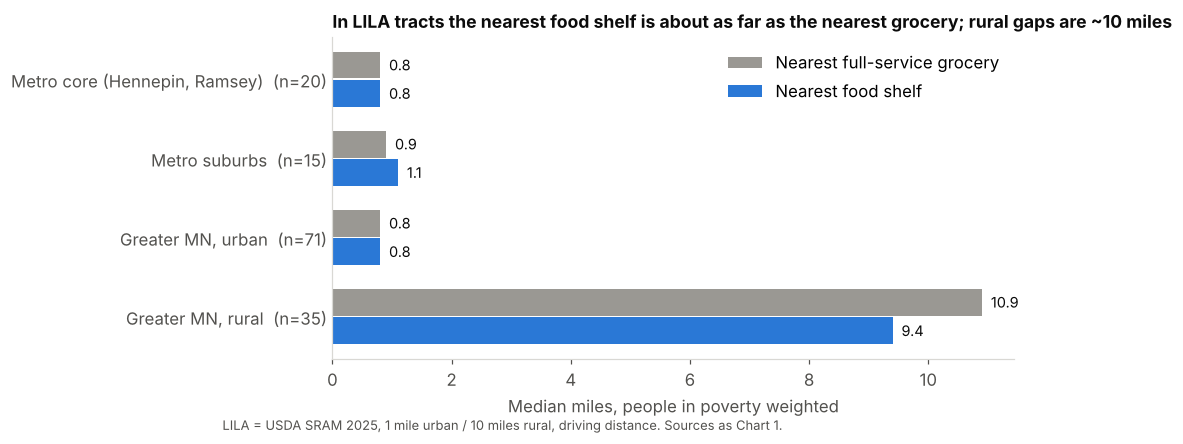

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.8))
pt = place_tbl[['median miles to full grocery', 'median miles to food shelf']]
y = np.arange(len(pt))[::-1]
ax.barh(y + 0.18, pt['median miles to full grocery'], height=0.34, color=GREY, label='Nearest full-service grocery')
ax.barh(y - 0.18, pt['median miles to food shelf'], height=0.34, color=ACCENT, label='Nearest food shelf')
for yy, (g, f) in zip(y, pt.values):
    ax.text(g + 0.15, yy + 0.18, f'{g:.1f}', va='center', fontsize=9.5, color=INK)
    ax.text(f + 0.15, yy - 0.18, f'{f:.1f}', va='center', fontsize=9.5, color=INK)
ax.set_yticks(y); ax.set_yticklabels([f'{p}  (n={n})' for p, n in zip(pt.index, place_tbl.tracts)])
ax.set_xlabel('Median miles, people in poverty weighted'); ax.tick_params(axis='y', length=0)
ax.legend(frameon=False, loc='upper right')
ax.set_title('In LILA tracts the nearest food shelf is about as far as the nearest grocery; rural gaps are ~10 miles', loc='left', fontsize=11.5)
fig.text(0, -0.06, 'LILA = USDA SRAM 2025, 1 mile urban / 10 miles rural, driving distance. Sources as Chart 1.', fontsize=8.5, color=INK2)
fig.savefig(f'{FIG}/q8_chart3_place.png'); plt.show()

## 4. Robustness: does the answer hold under other definitions?

Each row repeats the headline comparison (LILA vs low-income-not-low-access) under a different choice.

In [15]:
def headline(df, flag, dist='mi_foodshelf', lbs='lbs_per_poor_10mi', w='pop_poverty'):
    d = df[df.low_income == 1]
    a, b = d[d[flag] == 1], d[d[flag] == 0]
    thr_a = (a[dist] <= a.la_threshold_mi).astype(float); thr_b = (b[dist] <= b.la_threshold_mi).astype(float)
    return {'LILA tracts': len(a),
            'LILA: % within USDA distance': 100 * wmean(thr_a, a[w]), 'comparison: % within USDA distance': 100 * wmean(thr_b, b[w]),
            'LILA: median mi to food shelf': wmedian(a[dist], a[w]), 'comparison: median mi': wmedian(b[dist], b[w]),
            'LILA: lbs/person in poverty': wmean(a[lbs], a[w]), 'comparison: lbs/person in poverty': wmean(b[lbs], b[w])}

t['lila19_any'] = t.lila_2019
variants = {
    'Main: 2025, 1 & 10 mi, driving':           headline(t, 'DD_lila25_1And10'),
    '2025, 1 & 10 mi, straight-line':           headline(t, 'SD_lila25_1And10'),
    '2025, ½ & 10 mi, driving':                 headline(t, 'DD_lila25_halfAnd10'),
    '2025, 1 & 20 mi, driving':                 headline(t, 'DD_lila25_1And20'),
    '2025, vehicle access, driving':            headline(t, 'DD_lila25_Vehicle'),
    '2019 (brief\'s source), 1 & 10 mi':        headline(t, 'lila19_1And10'),
    'Fixed sites only (no outreach/mobile)':   headline(t, 'DD_lila25_1And10', dist='mi_foodshelf_fixed'),
    'Capacity within 5 mi':                     headline(t, 'DD_lila25_1And10', lbs='lbs_per_poor_5mi'),
    'Capacity within 20 mi':                    headline(t, 'DD_lila25_1And10', lbs='lbs_per_poor_20mi'),
    'Weights: 2019 low-income population':      headline(t.assign(pop_poverty=t.lowinc_2019), 'DD_lila25_1And10', lbs='lbs_per_lowinc19_10mi'),
}
robust = pd.DataFrame(variants).T.round(1)
robust.to_csv(f'{OUT}/q8_robustness.csv')
robust

,LILA tracts,LILA: % within USDA distance,comparison: % within USDA distance,LILA: median mi to food shelf,comparison: median mi,LILA: lbs/person in poverty,comparison: lbs/person in poverty
"Main: 2025, 1 & 10 mi, driving",141.0,64.7,71.6,0.9,0.8,240.7,290.0
"2025, 1 & 10 mi, straight-line",49.0,49.5,71.4,1.1,0.8,193.1,283.4
"2025, ½ & 10 mi, driving",291.0,57.5,86.3,0.9,0.6,270.7,283.6
"2025, 1 & 20 mi, driving",106.0,65.5,71.0,0.8,0.9,261.8,280.8
"2025, vehicle access, driving",104.0,64.9,71.5,0.8,0.8,288.4,271.4
"2019 (brief's source), 1 & 10 mi",164.0,59.7,73.9,1.1,0.8,226.0,297.5
Fixed sites only (no outreach/mobile),141.0,62.5,68.9,0.9,0.9,240.7,290.0
Capacity within 5 mi,141.0,64.7,71.6,0.9,0.8,260.1,278.8
Capacity within 20 mi,141.0,64.7,71.6,0.9,0.8,248.5,291.2
Weights: 2019 low-income population,141.0,61.2,70.1,1.0,0.9,92.6,125.0


## 5. Gap list: LILA tracts to act on

LILA in 2025 **or** 2019, with **no food shelf within the USDA distance**, ranked by people in poverty. These are candidates for a new site, a mobile route or extended hours.

In [16]:
gap = t[((t.lila == 1) | (t.lila_2019 == 1)) & (t.fs_within_la_threshold == 0)].copy()
nearest_city = sites.set_index('_id_site').City
gap['nearest food shelf'] = gap.nearest_site_id.map(nearest_city)
gap = gap.sort_values('pop_poverty', ascending=False)
gap_out = gap[['GEOID', 'county', 'place', 'Urban', 'lila', 'lila_2019', 'POP2020', 'pop_poverty', 'PovertyRate',
               'pct_no_vehicle', 'pct_snap_hh', 'mi_foodshelf', 'mi_grocery', 'nearest food shelf',
               'lbs_per_poor_10mi', 'tribal']].rename(columns={
    'GEOID': 'tract', 'Urban': 'urban', 'lila': 'LILA 2025', 'lila_2019': 'LILA 2019', 'POP2020': 'population',
    'pop_poverty': 'people in poverty', 'PovertyRate': 'poverty %', 'pct_no_vehicle': '% no vehicle',
    'pct_snap_hh': '% SNAP households', 'mi_foodshelf': 'miles to food shelf', 'mi_grocery': 'miles to grocery',
    'lbs_per_poor_10mi': 'lbs/person in poverty (10 mi)'})
gap_out.round(1).to_csv(f'{OUT}/q8_gap_tracts.csv', index=False)
print(f'{len(gap_out)} LILA tracts have no food shelf within the USDA distance; '
      f'{gap_out["people in poverty"].sum():,.0f} people in poverty live in them.')
gap_out.head(20).round(1)

117 LILA tracts have no food shelf within the USDA distance; 57,247 people in poverty live in them.


,tract,county,place,urban,LILA 2025,LILA 2019,population,people in poverty,poverty %,% no vehicle,% SNAP households,miles to food shelf,miles to grocery,nearest food shelf,lbs/person in poverty (10 mi),tribal
1320,27145000304,Stearns,"Greater MN, urban",1,0,1,5586,2128.3,38.1,12.7,54.4,1.7,1.2,Saint Cloud,160.0,0
120,27007940001,Beltrami,"Greater MN, rural",0,0,1,5506,1789.4,32.5,12.4,45.2,27.4,23.0,Bemidji,0.0,1
1083,27123037403,Ramsey,"Metro core (Hennepin, Ramsey)",1,1,1,6832,1721.7,25.2,13.3,27.4,1.8,1.4,St. Paul,277.0,0
890,27097780600,Morrison,"Greater MN, urban",1,1,1,5672,1219.5,21.5,12.6,22.3,1.3,0.5,Little Falls,127.8,0
1191,27137000301,St. Louis,"Greater MN, urban",1,1,0,5140,1177.1,22.9,18.8,6.7,1.8,0.5,Duluth,268.7,0
939,27109001401,Olmsted,"Greater MN, urban",1,0,1,4654,1168.2,25.1,17.0,17.8,1.3,1.0,Rochester,640.9,0
1319,27145000303,Stearns,"Greater MN, urban",1,0,1,2396,1145.3,47.8,5.5,19.4,1.4,1.0,Saint Cloud,160.0,0
1324,27145000502,Stearns,"Greater MN, urban",1,1,1,5928,1126.3,19.0,9.0,11.5,1.7,0.7,St. Cloud,160.0,0
626,27053026809,Hennepin,"Metro core (Hennepin, Ramsey)",1,0,1,4834,1111.8,23.0,20.8,15.8,1.1,1.3,Brooklyn Center,350.4,0
689,27053104002,Hennepin,"Metro core (Hennepin, Ramsey)",1,1,0,4309,1068.6,24.8,4.7,3.2,1.1,0.8,Minneapolis,366.9,0


In [17]:
gap_county = (gap_out.groupby('county').agg(tracts=('tract', 'size'), people_in_poverty=('people in poverty', 'sum'),
                                            median_miles_to_food_shelf=('miles to food shelf', 'median'))
              .sort_values('people_in_poverty', ascending=False).round(1))
gap_county.head(15)

,tracts,people_in_poverty,median_miles_to_food_shelf
county,,,
Hennepin,14,7210.4,1.2
Ramsey,13,7013.6,1.2
Stearns,7,6629.9,1.8
Anoka,10,4815.1,1.3
St. Louis,8,3746.1,3.1
Beltrami,4,2938.2,22.5
Becker,4,1898.7,12.1
Crow Wing,3,1844.8,1.3
Dakota,6,1809.1,2.2


## 6. Maps

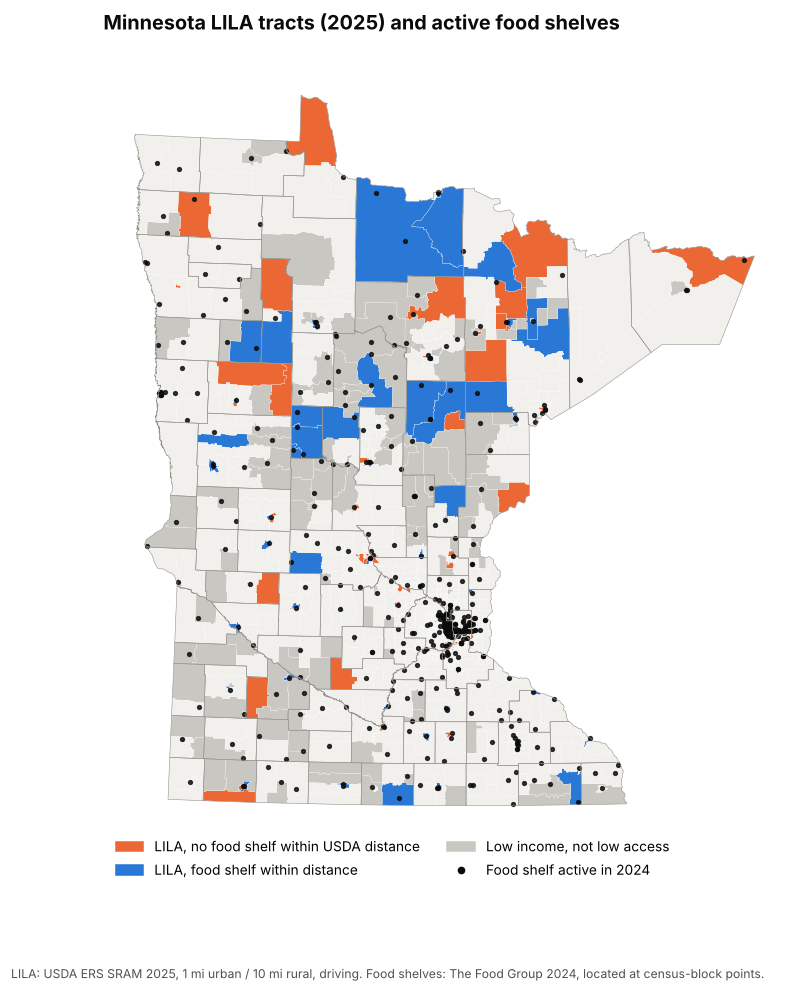

In [18]:
tr = gpd.read_file(f'{DATA}/tl_2024_27_tract/tl_2024_27_tract.shp').to_crs(26915)
tr = tr.merge(t[['GEOID', 'lila', 'lila_2019', 'low_income', 'fs_within_la_threshold']], on='GEOID', how='left')
tr['cat'] = np.select([(tr.lila == 1) & (tr.fs_within_la_threshold == 0), tr.lila == 1, tr.low_income == 1],
                      ['LILA, no food shelf within USDA distance', 'LILA, food shelf within distance', 'Low income, not low access'], 'Other')
cmap = {'LILA, no food shelf within USDA distance': ACCENT2, 'LILA, food shelf within distance': ACCENT,
        'Low income, not low access': '#c9c7c1', 'Other': '#f1f0ed'}
pts = gpd.GeoDataFrame(sites, geometry=gpd.points_from_xy(sites.s_lon, sites.s_lat), crs=4326).to_crs(26915)
counties = tr.dissolve(by='COUNTYFP')

def draw(ax, bounds=None, size=6):
    for c, col in cmap.items():
        sub = tr[tr.cat == c]
        if len(sub): sub.plot(ax=ax, color=col, edgecolor='white', linewidth=0.15)
    counties.boundary.plot(ax=ax, color='#8f8d88', linewidth=0.35)
    pts.plot(ax=ax, color=INK, markersize=size, marker='o', alpha=0.8)
    if bounds is not None: ax.set_xlim(bounds[0], bounds[2]); ax.set_ylim(bounds[1], bounds[3])
    ax.set_axis_off()

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
handles = [Patch(color=v, label=k) for k, v in cmap.items() if k != 'Other'] + \
          [Line2D([], [], marker='o', ls='', color=INK, markersize=4, label='Food shelf active in 2024')]

fig, ax = plt.subplots(figsize=(8, 9.5)); draw(ax)
ax.legend(handles=handles, loc='upper left', bbox_to_anchor=(0, 0.02), ncol=2, frameon=False, fontsize=9)
ax.set_title('Minnesota LILA tracts (2025) and active food shelves', loc='left')
fig.text(0.02, -0.01, 'LILA: USDA ERS SRAM 2025, 1 mi urban / 10 mi rural, driving. Food shelves: The Food Group 2024, located at census-block points.', fontsize=8, color=INK2)
fig.savefig(f'{FIG}/q8_map_statewide.png'); plt.show()

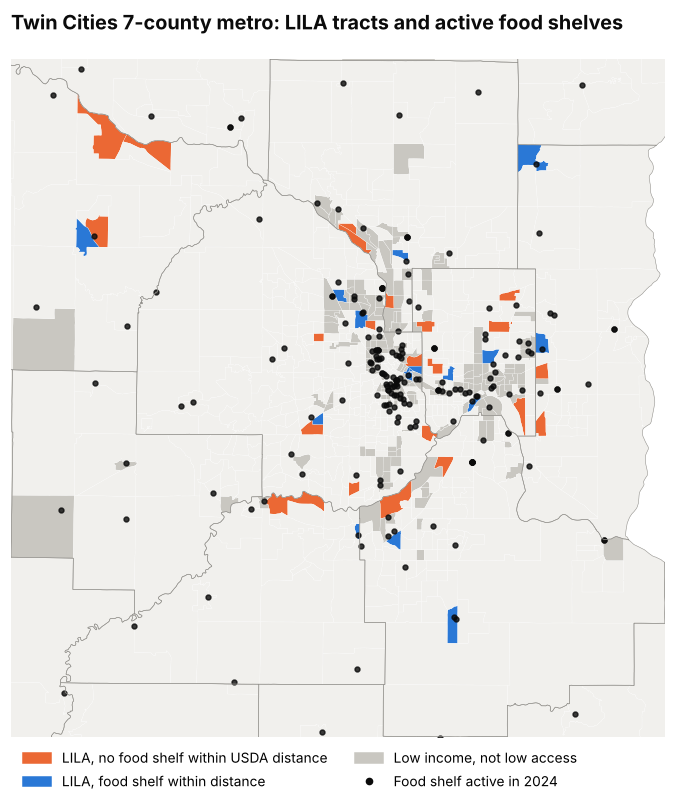

In [19]:
metro = tr[tr.COUNTYFP.isin(['053', '123', '003', '037', '163', '139', '019'])].total_bounds
fig, ax = plt.subplots(figsize=(8, 8)); draw(ax, metro, size=10)
ax.legend(handles=handles, loc='upper left', bbox_to_anchor=(0, 0.0), ncol=2, frameon=False, fontsize=9)
ax.set_title('Twin Cities 7-county metro: LILA tracts and active food shelves', loc='left')
fig.savefig(f'{FIG}/q8_map_twin_cities.png'); plt.show()

## 7. Numbers for the write-up

In [20]:
L, C = reach.loc['LILA'], reach.loc['Low income, not low access']
summary = {
    'LILA tracts (2025, driving)': int(L['tracts']),
    'People in poverty in LILA tracts': round(L['people in poverty']),
    '% of them within USDA distance of a food shelf': round(L['% within USDA distance of a food shelf'], 1),
    '... same for low-income, not low-access tracts': round(C['% within USDA distance of a food shelf'], 1),
    'Median miles to food shelf: LILA vs comparison': f"{L['median miles to food shelf']:.1f} vs {C['median miles to food shelf']:.1f}",
    'Median miles to grocery: LILA vs comparison': f"{L['median miles to full grocery']:.1f} vs {C['median miles to full grocery']:.1f}",
    'Food shelf capacity, lbs/person in poverty/yr: LILA vs comparison': f"{L['lbs / person in poverty / yr (10 mi)']:.0f} vs {C['lbs / person in poverty / yr (10 mi)']:.0f}",
    'Fill-or-repeat slope (log–log), 95% CI': f"{fit.params.log_gr:.2f} [{fit.conf_int().loc['log_gr',0]:.2f}, {fit.conf_int().loc['log_gr',1]:.2f}]",
    'Spearman rank correlation, grocery vs food shelf distance': round(rho_all, 2),
    'Gap tracts (LILA 2025 or 2019, no shelf within distance)': len(gap_out),
    'People in poverty in gap tracts': round(gap_out['people in poverty'].sum()),
}
pd.Series(summary).to_frame('value')

,value
"LILA tracts (2025, driving)",141
People in poverty in LILA tracts,85855
% of them within USDA distance of a food shelf,64.7
"... same for low-income, not low-access tracts",71.6
Median miles to food shelf: LILA vs comparison,0.9 vs 0.8
Median miles to grocery: LILA vs comparison,0.8 vs 0.6
"Food shelf capacity, lbs/person in poverty/yr: LILA vs comparison",241 vs 290
"Fill-or-repeat slope (log–log), 95% CI","0.58 [0.46, 0.69]"
"Spearman rank correlation, grocery vs food shelf distance",0.63
"Gap tracts (LILA 2025 or 2019, no shelf within distance)",117
